## 9. イベント発生までの時間の長さに関するモデル
### 9.2 生存函数の推定
#### 例題9.1
##### 1) データ全体

In [42]:
library(survival)
surv <- read.csv("./src/table_9_1.csv")


Attaching package: 'survival'


The following object is masked from 'package:boot':

    aml




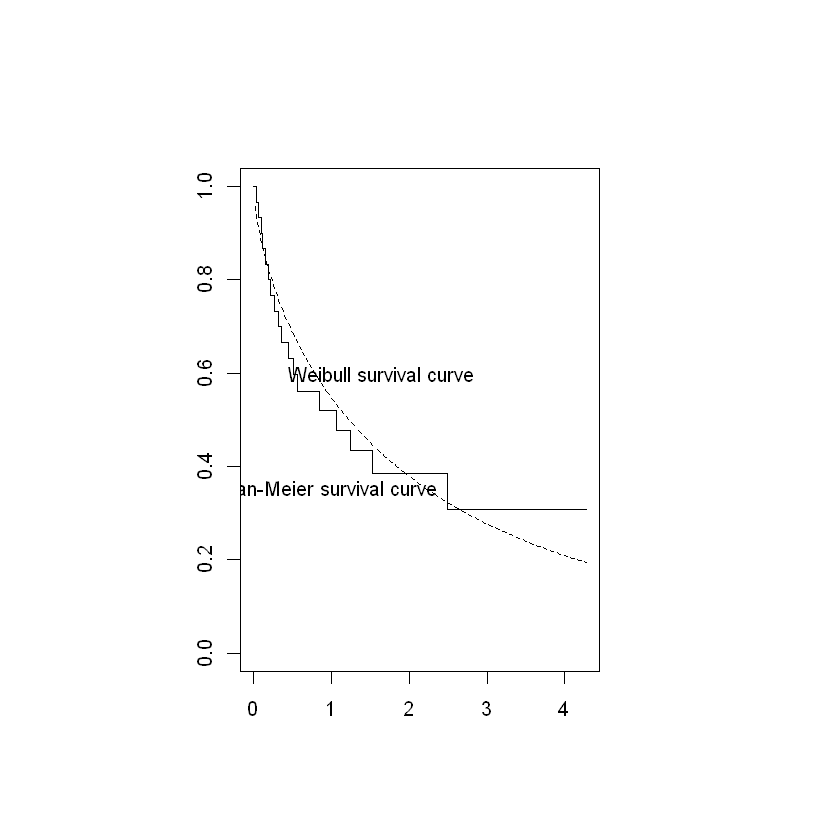

In [43]:
par(bg = "white")
# appendix B.5 (Figure 8.3)
#
# Newton Raphson method : Weibull distribution censored case
#
# u <- g(x)      : dLog(L)/d beta
# v <- dg(x)/dx  : d^2Log(L)/d^2 beta
#
# Variables: cans(= c), eta
#

par(mar=c(7, 10, 7, 10))
tt <- surv$day[surv$st==1] / 365  # event 発生のケースの生存時間 (Survival time for event cases)
zz <- surv$day / 365; z <- zz

# Initialize variables
r <- length(tt)
n0 <- length(zz)
eps <- 0.0001
x0 <- 1
x1 <- 2
x <- x0

yy <- matrix(0, 20, 2)
fpp <- matrix(0, 2, 2)
i <- 0

# Newton-Raphson Iteration Loop
while( abs( (x1 - x0) / x0 ) > eps ) {
  i <- i + 1

  # Compute elements for the derivatives
  a <- sum(zz^x)
  b <- sum(zz^x*log(zz))
  ap <- b
  bp <- sum(zz^x*log(zz)*log(zz))

  # h = first derivative (score function), hp = second derivative (Hessian)
  h <- 1/x + mean(log(tt)) - b/a
  hp <- -1/(x^2) - bp/a + (b/a)^2

  # Update x (beta estimate)
  x0 <- x
  x <- x - h/hp
  x1 <- x

  # Calculate scale parameter (eta / e) at current step
  e <- (sum(zz^x) / r)^(1/x)

  # Log-likelihood function value
  ff <- r*log(x/e) + (x - 1)*sum(log(tt/e)) - sum((zz/e)^x)

  # Store estimates and log-likelihood values
  yy[i, 1] <- x1
  yy[i, 2] <- ff
}

# Final Estimates and Hessian Component
cans <- x
g <- x
eta <- (sum(zz^x) / r)^(1/x)
e <- eta

fpp[1, 1] <- -r/(g^2) - sum((z/e)^g*(log(z/e))^2)
fpp[1, 2] <- -r/e + sum( (z/e)^g*(1/e + g/e*log(z/e)) )
fpp[2, 1] <- fpp[1, 2]
fpp[2, 2] <- -r*g/e/e - sum( g*(g+1)/e/e*(z/e)^g )
v <- solve(-fpp); var <- c(v[1, 1], v[2, 2])
#
se <- sqrt(var) # s.e. of estimates

# ouf <- survfit(surv$day, surv$st)
# plot.surv.fit(ouf, conf.int=F)
out <- survfit(Surv(day/365, st) ~ 1, data = surv)
plot(out, conf.int = FALSE)

li <- (1:195)*8/365
lines(li, exp(-(li/eta)^cans), lty=2)
text(600/365, 0.6, "Weibull survival curve")
text(300/365, 0.35, "Kaplan-Meier survival curve")

In [44]:
print(c(cans, eta))
print(se)
print(ff)

[1] 0.6903417 2.0942060
[1] 0.1340377 0.3641212
[1] -27.90533


##### 2) 治療群別
プレドニゾロン

[1] 0.6951264 3.3312290
[1] 0.2059696 0.8689037


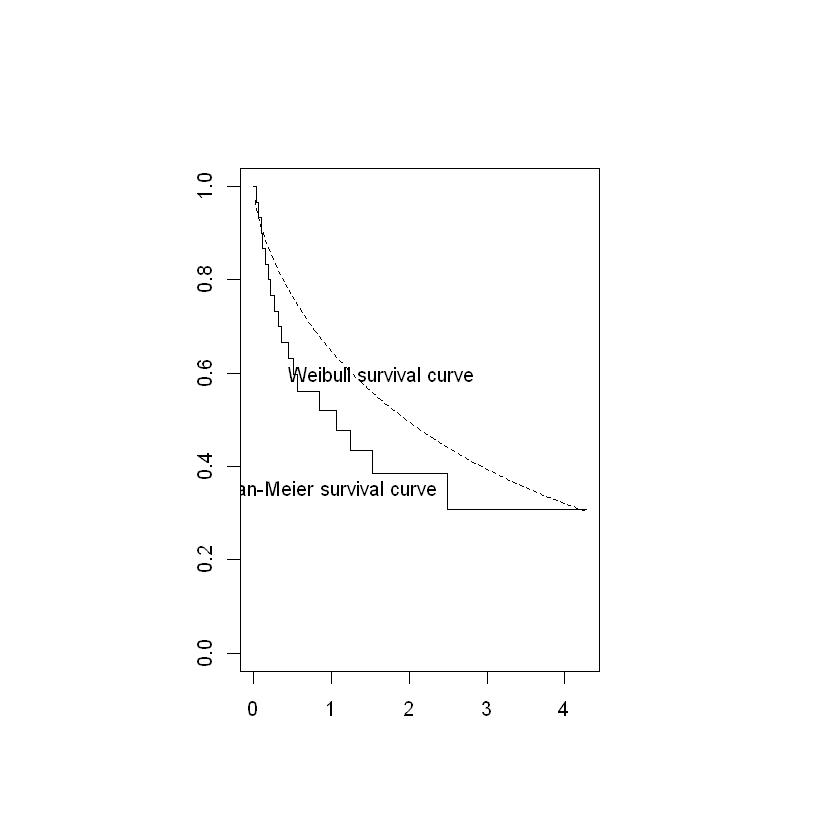

In [45]:
par(bg = "white")
# appendix B.5 (Figure 8.3)
#
# Newton Raphson method : Weibull distribution censored case
#
# u <- g(x)      : dLog(L)/d beta
# v <- dg(x)/dx  : d^2Log(L)/d^2 beta
#
# Variables: cans(= c), eta
#

par(mar=c(7, 10, 7, 10))
surv1 <- surv[surv$grp==1,]

tt <- surv1$day[surv1$st==1]/ 365  # event 発生のケースの生存時間 (Survival time for event cases)
zz <- surv1$day / 365; z <- zz

# Initialize variables
r <- length(tt)
n0 <- length(zz)
eps <- 0.0001
x0 <- 1
x1 <- 2
x <- x0

yy <- matrix(0, 20, 2)
fpp <- matrix(0, 2, 2)
i <- 0

# Newton-Raphson Iteration Loop
while( abs( (x1 - x0) / x0 ) > eps ) {
  i <- i + 1

  # Compute elements for the derivatives
  a <- sum(zz^x)
  b <- sum(zz^x*log(zz))
  ap <- b
  bp <- sum(zz^x*log(zz)*log(zz))

  # h = first derivative (score function), hp = second derivative (Hessian)
  h <- 1/x + mean(log(tt)) - b/a
  hp <- -1/(x^2) - bp/a + (b/a)^2

  # Update x (beta estimate)
  x0 <- x
  x <- x - h/hp
  x1 <- x

  # Calculate scale parameter (eta / e) at current step
  e <- (sum(zz^x) / r)^(1/x)

  # Log-likelihood function value
  ff <- r*log(x/e) + (x - 1)*sum(log(tt/e)) - sum((zz/e)^x)

  # Store estimates and log-likelihood values
  yy[i, 1] <- x1
  yy[i, 2] <- ff
}

# Final Estimates and Hessian Component
cans <- x
g <- x
eta <- (sum(zz^x) / r)^(1/x)
e <- eta

fpp[1, 1] <- -r/(g^2) - sum((z/e)^g*(log(z/e))^2)
fpp[1, 2] <- -r/e + sum( (z/e)^g*(1/e + g/e*log(z/e)) )
fpp[2, 1] <- fpp[1, 2]
fpp[2, 2] <- -r*g/e/e - sum( g*(g+1)/e/e*(z/e)^g )
v <- solve(-fpp); var <- c(v[1, 1], v[2, 2])
#
se <- sqrt(var) # s.e. of estimates

# ouf <- survfit(surv$day, surv$st)
# plot.surv.fit(ouf, conf.int=F)
out <- survfit(Surv(day/365, st) ~ 1, data = surv)
plot(out, conf.int = FALSE)

li <- (1:195)*8/365
lines(li, exp(-(li/eta)^cans), lty=2)
text(600/365, 0.6, "Weibull survival curve")
text(300/365, 0.35, "Kaplan-Meier survival curve")

print(c(cans, eta))
print(se)

プラセボ群

[1] 0.795185 1.182308
[1] 0.2100034 0.2518713


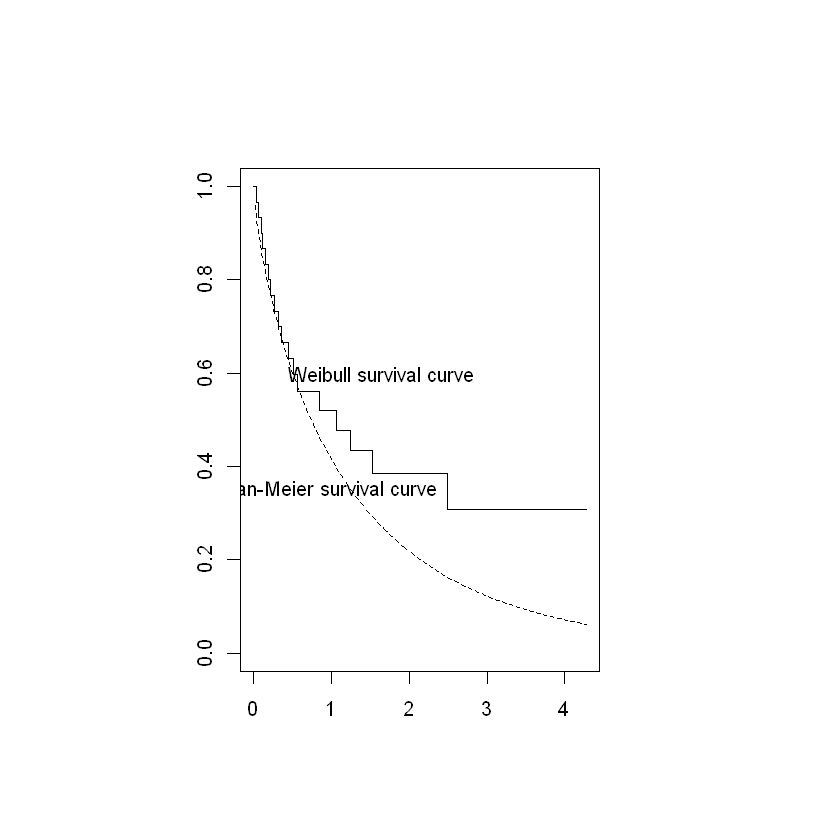

In [46]:
par(bg = "white")
# appendix B.5 (Figure 8.3)
#
# Newton Raphson method : Weibull distribution censored case
#
# u <- g(x)      : dLog(L)/d beta
# v <- dg(x)/dx  : d^2Log(L)/d^2 beta
#
# Variables: cans(= c), eta
#

par(mar=c(7, 10, 7, 10))
surv0 <- surv[surv$grp==0,]

tt <- surv0$day[surv0$st==1]/ 365  # event 発生のケースの生存時間 (Survival time for event cases)
zz <- surv0$day / 365; z <- zz

# Initialize variables
r <- length(tt)
n0 <- length(zz)
eps <- 0.0001
x0 <- 1
x1 <- 2
x <- x0

yy <- matrix(0, 20, 2)
fpp <- matrix(0, 2, 2)
i <- 0

# Newton-Raphson Iteration Loop
while( abs( (x1 - x0) / x0 ) > eps ) {
  i <- i + 1

  # Compute elements for the derivatives
  a <- sum(zz^x)
  b <- sum(zz^x*log(zz))
  ap <- b
  bp <- sum(zz^x*log(zz)*log(zz))

  # h = first derivative (score function), hp = second derivative (Hessian)
  h <- 1/x + mean(log(tt)) - b/a
  hp <- -1/(x^2) - bp/a + (b/a)^2

  # Update x (beta estimate)
  x0 <- x
  x <- x - h/hp
  x1 <- x

  # Calculate scale parameter (eta / e) at current step
  e <- (sum(zz^x) / r)^(1/x)

  # Log-likelihood function value
  ff <- r*log(x/e) + (x - 1)*sum(log(tt/e)) - sum((zz/e)^x)

  # Store estimates and log-likelihood values
  yy[i, 1] <- x1
  yy[i, 2] <- ff
}

# Final Estimates and Hessian Component
cans <- x
g <- x
eta <- (sum(zz^x) / r)^(1/x)
e <- eta

fpp[1, 1] <- -r/(g^2) - sum((z/e)^g*(log(z/e))^2)
fpp[1, 2] <- -r/e + sum( (z/e)^g*(1/e + g/e*log(z/e)) )
fpp[2, 1] <- fpp[1, 2]
fpp[2, 2] <- -r*g/e/e - sum( g*(g+1)/e/e*(z/e)^g )
v <- solve(-fpp); var <- c(v[1, 1], v[2, 2])
#
se <- sqrt(var) # s.e. of estimates

# ouf <- survfit(surv$day, surv$st)
# plot.surv.fit(ouf, conf.int=F)
out <- survfit(Surv(day/365, st) ~ 1, data = surv)
plot(out, conf.int = FALSE)

li <- (1:195)*8/365
lines(li, exp(-(li/eta)^cans), lty=2)
text(600/365, 0.6, "Weibull survival curve")
text(300/365, 0.35, "Kaplan-Meier survival curve")

print(c(cans, eta))
print(se)

### 9.3 比例ハザードモデル
#### 例題9.2

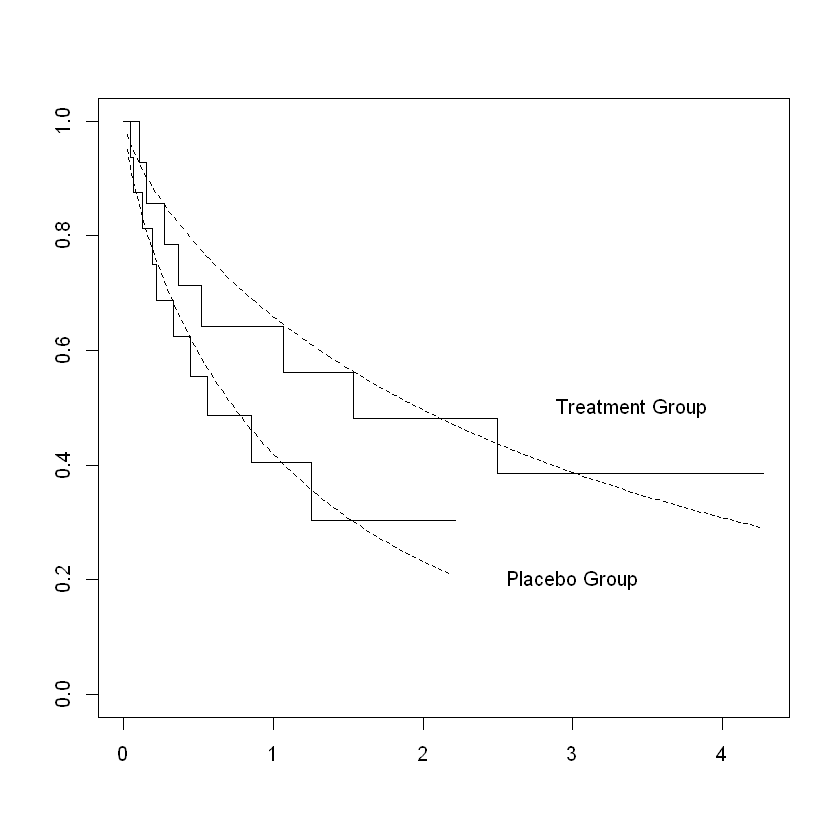

In [47]:
par(bg = "white")
# appendix B.6 ( Figure B.4 )
#
# Newton Raphson method :
# Weibull proportional hazard model
#
# u <- g(x)       : dlog(L)/d beta
# v <- dg(x)/dx    : d^2log(L)/d^2 beta
#
# Variables: g (= gamma/shape), e (= eta/scale), b (= beta/coefficients)

r  <- length(surv$day[surv$st == 1])
tj <- surv$day[surv$st == 1]/365
xj <- surv$grp[surv$st == 1]
x  <- surv$grp
z  <- surv$day/365

eps  <- 0.0001
nn   <- 150
fold <- c(0.5, 2, 0.2)
fpp  <- matrix(0, 3, 3)
xx   <- matrix(0, nn, 4)
fp   <- 1:3

for (i in 1:nn) {
  g <- fold[1]
  e <- fold[2]
  b <- fold[3]

  # Gradient vector (First derivatives)
  fp[1] <- r/g + sum(log(tj/e)) - sum(exp(b*x)*(z/e)^g*log(z/e))
  fp[2] <- -r*g/e + sum(exp(b*x)*(z/e)^g*g/e)
  fp[3] <- sum(xj) - sum(x*exp(b*x)*(z/e)^g)

  # Hessian matrix (Second derivatives)
  fpp[1,1] <- -r/g/g - sum(exp(b*x)*(z/e)^g*(log(z/e))^2)
  fpp[1,2] <- -r/e + sum(exp(b*x)*(z/e)^g*(1/e + g/e*log(z/e)))
  fpp[1,3] <- -sum(x*exp(b*x)*(z/e)^g*log(z/e))

  fpp[2,1] <- fpp[1,2]
  fpp[2,2] <- r*g/e/e - sum(exp(b*x)*g*(g+1) / e / e*(z/e)^g)
  fpp[2,3] <- -sum(x*exp(b*x)*(g/e)*(z/e)^g)

  fpp[3,1] <- fpp[1,3]
  fpp[3,2] <- fpp[2,3]
  fpp[3,3] <- -sum(x*x*exp(b*x)*(z/e)^g)

  # Newton-Raphson update step with a learning rate/damping factor of 0.2
  fnew <- fold - solve(fpp) %*% fp*0.2

  # Log-likelihood function calculation
  ff <- r*log(g/e) + (g - 1)*sum(log(tj/e)) + sum(b*xj) - sum(exp(b*x)*(z/e)^g)

  # Store history
  xx[i, 1] <- fnew[1]
  xx[i, 2] <- fnew[2]
  xx[i, 3] <- fnew[3]
  xx[i, 4] <- ff

  fold <- fnew
}

g <- fnew[1]
e <- fnew[2]
b <- fnew[3]


# ouf <- surv.fit(surv$day, surv$st, surv$grp)
# plot.surv.fit(ouf, conf.int=F)
out <- survfit(Surv(day/365, st) ~ grp, data = surv)
plot(out, conf.int = FALSE)

li <- (1:100)*8/365
lines(li, exp(-(li/e)^g), lty=2)

li <- (1:195)*8/365
lines(li, (exp(-(li/e)^g))^exp(b), lty=2)

text(3.4, 0.5, "Treatment Group")
text(3, 0.2, "Placebo Group")


In [48]:
print(c(g,e,b))

[1]  0.7477399  1.2058586 -0.7350836


In [49]:
v <- solve(-fpp); var <- c(v[1, 1], v[2, 2], v[3, 3])
#
se <- sqrt(var) # s.e. of estimates

print(se)

[1] 0.1554240 0.5332746 0.5092956


In [50]:
print(ff)

[1] -26.77651


#### 例題9.4

In [51]:
res <- coxph(Surv(day, st) ~ grp, data = surv)
summary(res)

Call:
coxph(formula = Surv(day, st) ~ grp, data = surv)

  n= 30, number of events= 18 

       coef exp(coef) se(coef)      z Pr(>|z|)
grp -0.5412    0.5821   0.5000 -1.082    0.279

    exp(coef) exp(-coef) lower .95 upper .95
grp    0.5821      1.718    0.2184     1.551

Concordance= 0.57  (se = 0.061 )
Likelihood ratio test= 1.2  on 1 df,   p=0.3
Wald test            = 1.17  on 1 df,   p=0.3
Score (logrank) test = 1.2  on 1 df,   p=0.3


In [52]:
res <- coxph(Surv(day, st) ~ grp + alb + drink, data = surv)
summary(res)

Call:
coxph(formula = Surv(day, st) ~ grp + alb + drink, data = surv)

  n= 30, number of events= 18 

         coef exp(coef) se(coef)      z Pr(>|z|)    
grp   -1.1133    0.3285   0.6069 -1.834   0.0666 .  
alb   -0.4153    0.6601   0.1023 -4.061  4.9e-05 ***
drink  1.3085    3.7005   0.6585  1.987   0.0469 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

      exp(coef) exp(-coef) lower .95 upper .95
grp      0.3285     3.0444   0.09998    1.0792
alb      0.6601     1.5149   0.54020    0.8067
drink    3.7005     0.2702   1.01790   13.4527

Concordance= 0.88  (se = 0.027 )
Likelihood ratio test= 36.66  on 3 df,   p=5e-08
Wald test            = 21.82  on 3 df,   p=7e-05
Score (logrank) test = 37.99  on 3 df,   p=3e-08
